# 04 - U-Net Improvements

## Objective

This notebook investigates whether data augmentation improves the
generalization of the baseline U-Net for binary brain tumor segmentation.

The baseline achieved:
- Validation Dice: 0.8351
- Test Dice: 0.8209
- Test IoU: 0.7412
- Glioma test Dice: 0.6698

Glioma segmentation was identified as the main weakness, with
some test images receiving near-zero Dice scores.

## Experimental Strategy

The experiment keeps the original architecture, preprocessing,
dataset partitions, loss function, and optimizer unchanged.

Only the training pipeline is modified to introduce synchronized
geometric augmentation of MRI images and segmentation masks.

Model selection will rely exclusively on validation performance.

The corrected test partition will remain excluded from
experimentation and model selection.

## 4.1 - Data Pipeline Reconstruction

The original training, validation, and test partitions are
reused from the data preparation artifacts.

Preprocessing parameters are loaded from the saved JSON
configuration to ensure consistency with the baseline.

Data augmentation will subsequently be applied to the training
partition only.

In [ ]:
from pathlib import Path
import urllib.request
import json
import pandas as pd
import tensorflow as tf

REPO = "nouraastafofana-droid/brain-tumor-mri-segmentation"
BRANCH = "main"

ARTIFACT_DIR = Path("/content/artifacts/data_preparation")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    f"https://raw.githubusercontent.com/"
    f"{REPO}/{BRANCH}/artifacts/data_preparation"
)

filenames = [
    "train.csv",
    "val.csv",
    "test.csv",
    "preprocessing_config.json",
    "split_summary.json"
]

for filename in filenames:
    urllib.request.urlretrieve(
        f"{BASE_URL}/{filename}",
        ARTIFACT_DIR / filename
    )

train_df = pd.read_csv(ARTIFACT_DIR / "train.csv")
val_df = pd.read_csv(ARTIFACT_DIR / "val.csv")
test_df = pd.read_csv(ARTIFACT_DIR / "test.csv")

with open(ARTIFACT_DIR / "preprocessing_config.json") as f:
    config = json.load(f)

with open(ARTIFACT_DIR / "split_summary.json") as f:
    split_summary = json.load(f)

print("Data preparation artifacts loaded.")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Data preparation artifacts loaded.
Train: 3345
Validation: 588
Test: 853


In [ ]:
from google.colab import userdata
import os

DATA_ROOT = Path("/content/data")
BRISC_ROOT = DATA_ROOT / "brisc2025"

if not (BRISC_ROOT / "manifest.csv").exists():

    os.environ["KAGGLE_API_TOKEN"] = userdata.get(
        "KAGGLE_API_TOKEN"
    )

    DATA_ROOT.mkdir(parents=True, exist_ok=True)

    !kaggle datasets download -d briscdataset/brisc2025 -p /content/data --unzip

assert (BRISC_ROOT / "manifest.csv").exists(), (
    "BRISC 2025 dataset not found."
)

print("BRISC dataset available.")

Dataset URL: https://www.kaggle.com/datasets/briscdataset/brisc2025
License(s): Attribution 4.0 International (CC BY 4.0)
100% 250M/250M [00:11<00:00, 22.1MB/s]

BRISC dataset available.


In [ ]:
IMAGE_SIZE = tuple(config["image_size"])
BATCH_SIZE = config["batch_size"]
MASK_THRESHOLD = config["mask_threshold"]
RANDOM_STATE = config["random_state"]

AUTOTUNE = tf.data.AUTOTUNE


def preprocess_pair(image_path, mask_path):

    # Load MRI
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    # Load mask
    mask = tf.io.read_file(mask_path)
    mask = tf.io.decode_png(mask, channels=1)

    # Resize
    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method=config["image_interpolation"]
    )

    mask = tf.image.resize(
        mask,
        IMAGE_SIZE,
        method=config["mask_interpolation"]
    )

    # Normalize MRI and binarize mask
    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask >= MASK_THRESHOLD, tf.float32)

    return image, mask


def build_dataset(df, training=False):

    image_paths = [
        str(BRISC_ROOT / path.replace("\\", "/"))
        for path in df["image_relative_path"]
    ]

    mask_paths = [
        str(BRISC_ROOT / path.replace("\\", "/"))
        for path in df["mask_relative_path"]
    ]

    assert all(Path(p).is_file() for p in image_paths)
    assert all(Path(p).is_file() for p in mask_paths)

    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        preprocess_pair,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = build_dataset(train_df, training=True)
val_ds = build_dataset(val_df)
test_ds = build_dataset(test_df)

print("Original datasets reconstructed.")

Original datasets reconstructed.


In [ ]:
for name, dataset in [
    ("Train", train_ds),
    ("Validation", val_ds),
    ("Test", test_ds)
]:
    images, masks = next(iter(dataset))

    print(f"\n{name}:")
    print("Images:", images.shape)
    print("Masks:", masks.shape)
    print(
        "Image range:",
        float(tf.reduce_min(images)),
        float(tf.reduce_max(images))
    )
    print(
        "Mask values:",
        tf.unique(tf.reshape(masks, [-1]))[0].numpy()
    )

    assert images.shape[1:] == (256, 256, 1)
    assert masks.shape[1:] == (256, 256, 1)

    assert tf.reduce_min(images) >= 0
    assert tf.reduce_max(images) <= 1

    assert tf.reduce_all(
        tf.logical_or(masks == 0, masks == 1)
    )

print("\nData pipeline validated.")


Train:
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)
Image range: 0.0 0.9823529124259949
Mask values: [0. 1.]

Validation:
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)
Image range: 0.0 0.9784313440322876
Mask values: [0. 1.]

Test:
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)
Image range: 0.0 0.9745097756385803
Mask values: [0. 1.]

Data pipeline validated.


## 4.2 - Synchronized Data Augmentation

Geometric augmentation is applied exclusively to the training dataset.

Random horizontal flips and 90-degree rotations are applied
identically to MRI images and their corresponding segmentation masks.

This preserves pixel-level alignment and binary mask values.

Validation and test images remain unchanged to ensure consistent
evaluation against the baseline.

In [ ]:
def augment_pair(image, mask):

    # Random horizontal flip
    flip = tf.random.uniform(()) < 0.5

    image = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(image),
        lambda: image
    )

    mask = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(mask),
        lambda: mask
    )

    # Random rotation: 0, 90, 180 or 270 degrees
    k = tf.random.uniform(
        shape=(),
        minval=0,
        maxval=4,
        dtype=tf.int32
    )

    image = tf.image.rot90(image, k=k)
    mask = tf.image.rot90(mask, k=k)

    return image, mask

In [ ]:
train_aug_ds = (
    train_ds
    .unbatch()
    .map(
        augment_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Augmented training dataset created.")

images_aug, masks_aug = next(iter(train_aug_ds))

print("Images:", images_aug.shape)
print("Masks:", masks_aug.shape)
print(
    "Mask values:",
    tf.unique(tf.reshape(masks_aug, [-1]))[0].numpy()
)

assert images_aug.shape[1:] == (256, 256, 1)
assert masks_aug.shape[1:] == (256, 256, 1)
assert tf.reduce_all(
    tf.logical_or(masks_aug == 0, masks_aug == 1)
)

print("Augmentation pipeline validated.")

Augmented training dataset created.
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)
Mask values: [0. 1.]
Augmentation pipeline validated.


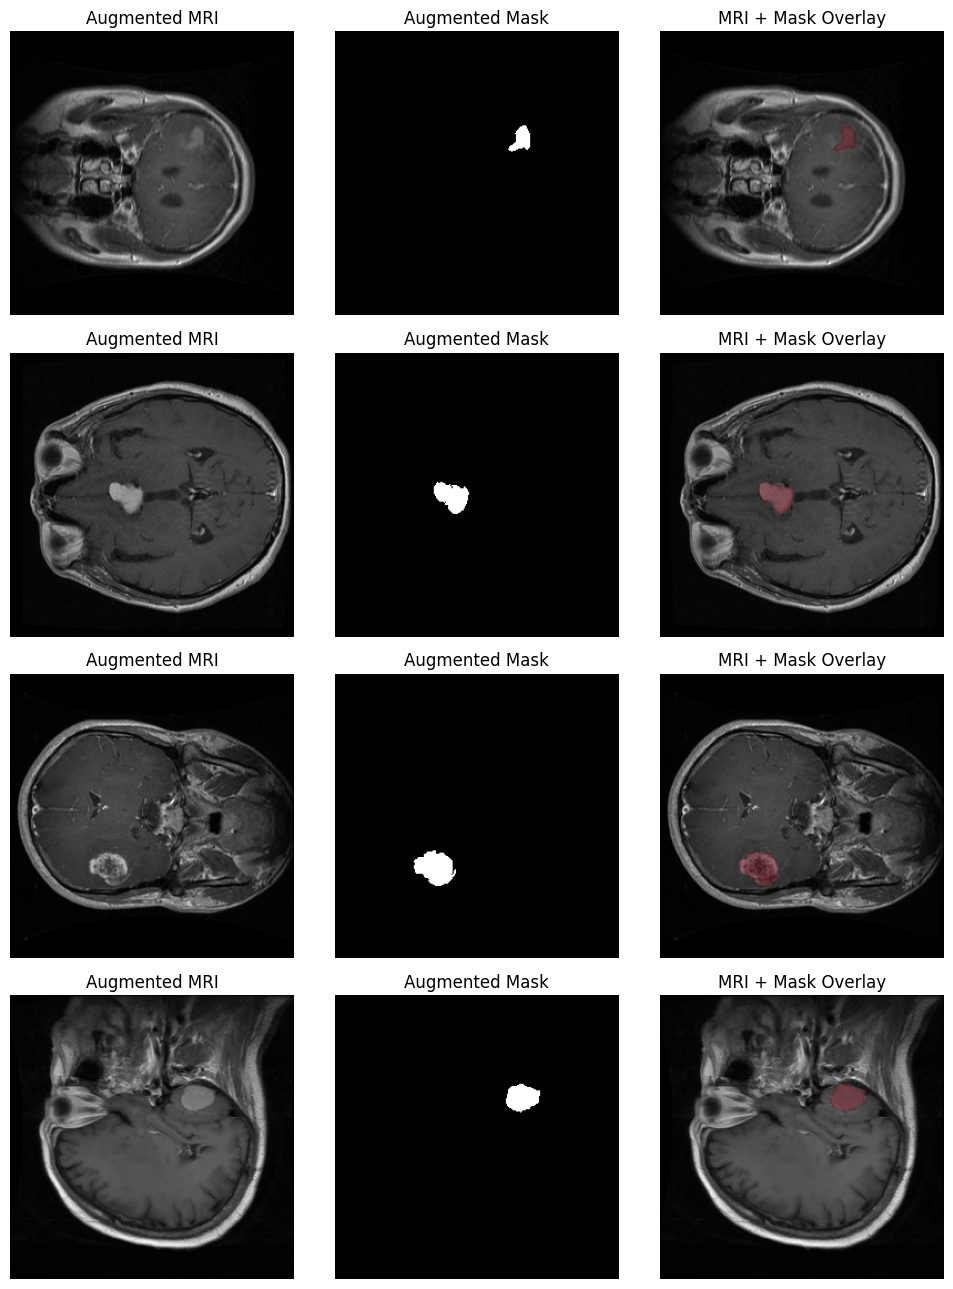

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

images_aug, masks_aug = next(iter(train_aug_ds))

fig, axes = plt.subplots(
    4, 3,
    figsize=(10, 13)
)

for i in range(4):

    image = images_aug[i, :, :, 0].numpy()
    mask = masks_aug[i, :, :, 0].numpy()

    overlay = np.ma.masked_where(mask == 0, mask)

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title("Augmented MRI")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Augmented Mask")

    axes[i, 2].imshow(image, cmap="gray")
    axes[i, 2].imshow(
        overlay,
        cmap="Reds",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("MRI + Mask Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 4.3 - U-Net Architecture and Compilation

The baseline U-Net architecture is reconstructed without modifications.

The model uses four encoder stages, a bottleneck, and four decoder
stages with skip connections.

The same BCE + Dice loss, Adam optimizer, and segmentation metrics
are retained to isolate the effect of data augmentation.

The augmented model is initialized from scratch rather than
fine-tuned from the baseline checkpoint.

In [ ]:
from tensorflow.keras import layers, Model


def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = layers.Conv2D(
        filters, 3,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    return x


def build_unet(input_shape=(256, 256, 1)):

    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    bottleneck = conv_block(p4, 512)

    # Decoder
    u4 = layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(bottleneck)
    u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c5)
    u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c6)
    u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c7)
    u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c8)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="unet_augmented"
    )


tf.keras.utils.set_random_seed(RANDOM_STATE)

model_aug = build_unet()

print("Total parameters:", model_aug.count_params())
print("Input shape:", model_aug.input_shape)
print("Output shape:", model_aug.output_shape)

Total parameters: 7759521
Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)


In [ ]:
SMOOTH = 1e-6


def dice_coefficient(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)

    intersection = tf.reduce_sum(
        y_true * y_pred, axis=[1, 2, 3]
    )

    denominator = (
        tf.reduce_sum(y_true, axis=[1, 2, 3])
        + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    )

    dice = (
        2.0 * intersection + SMOOTH
    ) / (denominator + SMOOTH)

    return tf.reduce_mean(dice)


def iou_coefficient(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)

    intersection = tf.reduce_sum(
        y_true * y_pred, axis=[1, 2, 3]
    )

    union = (
        tf.reduce_sum(y_true, axis=[1, 2, 3])
        + tf.reduce_sum(y_pred, axis=[1, 2, 3])
        - intersection
    )

    iou = (
        intersection + SMOOTH
    ) / (union + SMOOTH)

    return tf.reduce_mean(iou)


def bce_dice_loss(y_true, y_pred):

    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(
            y_true, y_pred
        )
    )

    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(
        y_true * y_pred, axis=[1, 2, 3]
    )

    denominator = (
        tf.reduce_sum(y_true, axis=[1, 2, 3])
        + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    )

    soft_dice = (
        2.0 * intersection + SMOOTH
    ) / (denominator + SMOOTH)

    return bce + (1.0 - tf.reduce_mean(soft_dice))


model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=bce_dice_loss,
    metrics=[
        dice_coefficient,
        iou_coefficient
    ]
)

print("Augmented U-Net compiled successfully.")

Augmented U-Net compiled successfully.


In [ ]:
assert model_aug.count_params() == 7759521

assert model_aug.input_shape == (
    None, 256, 256, 1
)

assert model_aug.output_shape == (
    None, 256, 256, 1
)

print("Architecture validated.")
print("Ready for augmented training.")

Architecture validated.
Ready for augmented training.


## 4.4 - Training with Data Augmentation

The augmented U-Net is trained from scratch using the same
training configuration as the baseline model.

Only the training dataset includes synchronized geometric
augmentation. The validation dataset remains unchanged.

Model checkpoints and training logs are saved separately
from the baseline to preserve both experiments.

The best model is selected using validation loss.

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AUG_CHECKPOINT = CHECKPOINT_DIR / "unet_augmented_best.keras"
AUG_TRAINING_LOG = CHECKPOINT_DIR / "unet_augmented_training_log.csv"

print("Checkpoint:", AUG_CHECKPOINT)
print("Training log:", AUG_TRAINING_LOG)

Mounted at /content/drive
Checkpoint: /content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints/unet_augmented_best.keras
Training log: /content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints/unet_augmented_training_log.csv


In [ ]:
callbacks_aug = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(AUG_CHECKPOINT),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(AUG_TRAINING_LOG)
    )
]

print("Training callbacks configured.")

Training callbacks configured.


In [ ]:
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

history_aug = model_aug.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_aug,
    verbose=1
)

In [ ]:
import numpy as np

best_epoch = int(np.argmin(history_aug.history["val_loss"])) + 1

print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(history_aug.history["val_loss"]), 4)
)
print(
    "Validation Dice at best epoch:",
    round(history_aug.history["val_dice_coefficient"][best_epoch - 1], 4)
)
print(
    "Validation IoU at best epoch:",
    round(history_aug.history["val_iou_coefficient"][best_epoch - 1], 4)
)

Best epoch: 30
Best validation loss: 0.1843
Validation Dice at best epoch: 0.8418
Validation IoU at best epoch: 0.764


## 4.5 - Validation Performance by Tumor Type

The augmented U-Net is evaluated on the unchanged validation set.

Dice and IoU are calculated for each image, then aggregated by
tumor type and imaging plane.

This analysis investigates whether augmentation improves the
model's robustness, particularly for glioma segmentation.

The held-out test set is not used for model selection.

In [ ]:
# Restore the best augmented checkpoint
model_aug = tf.keras.models.load_model(
    str(AUG_CHECKPOINT),
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient,
        "iou_coefficient": iou_coefficient
    }
)

validation_results = val_df.copy().reset_index(drop=True)

dice_scores = []
iou_scores = []

for images, masks in val_ds:

    predictions = model_aug.predict(images, verbose=0)

    y_true = masks.numpy() >= 0.5
    y_pred = predictions >= 0.5

    for true_mask, pred_mask in zip(y_true, y_pred):

        intersection = np.logical_and(
            true_mask, pred_mask
        ).sum()

        true_sum = true_mask.sum()
        pred_sum = pred_mask.sum()

        union = np.logical_or(
            true_mask, pred_mask
        ).sum()

        dice = (
            (2 * intersection + 1e-6)
            / (true_sum + pred_sum + 1e-6)
        )

        iou = (
            (intersection + 1e-6)
            / (union + 1e-6)
        )

        dice_scores.append(float(dice))
        iou_scores.append(float(iou))

validation_results["dice"] = dice_scores
validation_results["iou"] = iou_scores

assert len(validation_results) == len(val_df)

print("Validation images:", len(validation_results))
print("Mean Dice:", round(validation_results["dice"].mean(), 4))
print("Mean IoU:", round(validation_results["iou"].mean(), 4))

Validation images: 588
Mean Dice: 0.8417
Mean IoU: 0.764


In [ ]:
print("Performance by tumor type:")

display(
    validation_results
    .groupby("tumor_label")[["dice", "iou"]]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

print("\nPerformance by imaging plane:")

display(
    validation_results
    .groupby("plane_label")[["dice", "iou"]]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

Performance by tumor type:


dice                           iou                        
            count    mean  median     std count    mean  median     std
tumor_label                                                            
glioma        160  0.7004  0.7884  0.2825   160  0.5983  0.6507  0.2802
meningioma    211  0.9233  0.9527  0.1236   211  0.8727  0.9096  0.1362
pituitary     217  0.8666  0.9080  0.1175   217  0.7806  0.8315  0.1563


Performance by imaging plane:


dice                           iou                        
            count    mean  median     std count    mean  median     std
plane_label                                                            
axial         196  0.8146  0.9113  0.2429   196  0.7377  0.8371  0.2526
coronal       189  0.8416  0.9118  0.1741   189  0.7560  0.8379  0.2019
sagittal      203  0.8680  0.9327  0.1741   203  0.7969  0.8738  0.2005

## 4.6 - Paired Validation Comparison

The baseline and augmented U-Net models are compared on the
same 588 validation images.

Per-image Dice and IoU scores are calculated using identical
evaluation procedures.

The comparison focuses on overall performance, tumor-specific
differences, and the frequency of severe glioma segmentation
failures.

In [ ]:
BASELINE_CHECKPOINT = CHECKPOINT_DIR / "unet_baseline_best.keras"

model_baseline = tf.keras.models.load_model(
    str(BASELINE_CHECKPOINT),
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient,
        "iou_coefficient": iou_coefficient
    }
)

baseline_dice = []
baseline_iou = []

for images, masks in val_ds:

    predictions = model_baseline.predict(images, verbose=0)

    y_true = masks.numpy() >= 0.5
    y_pred = predictions >= 0.5

    for true_mask, pred_mask in zip(y_true, y_pred):

        intersection = np.logical_and(
            true_mask, pred_mask
        ).sum()

        union = np.logical_or(
            true_mask, pred_mask
        ).sum()

        dice = (
            (2 * intersection + 1e-6)
            / (true_mask.sum() + pred_mask.sum() + 1e-6)
        )

        iou = (
            (intersection + 1e-6)
            / (union + 1e-6)
        )

        baseline_dice.append(float(dice))
        baseline_iou.append(float(iou))

validation_results["baseline_dice"] = baseline_dice
validation_results["baseline_iou"] = baseline_iou

validation_results["dice_gain"] = (
    validation_results["dice"]
    - validation_results["baseline_dice"]
)

print("Overall comparison:")
print(
    validation_results[
        ["baseline_dice", "dice", "dice_gain"]
    ].mean().round(4)
)

print("\nComparison by tumor type:")

display(
    validation_results.groupby("tumor_label")[
        ["baseline_dice", "dice", "dice_gain"]
    ].mean().round(4)
)

glioma_val = validation_results[
    validation_results["tumor_label"] == "glioma"
]

print("\nGlioma severe failures (Dice < 0.2):")
print(
    "Baseline:",
    (glioma_val["baseline_dice"] < 0.2).sum()
)
print(
    "Augmented:",
    (glioma_val["dice"] < 0.2).sum()
)

print("\nGlioma cases improved:")
print((glioma_val["dice_gain"] > 0).sum(), "/", len(glioma_val))

Overall comparison:
baseline_dice    0.8353
dice             0.8417
dice_gain        0.0064
dtype: float64

Comparison by tumor type:


,baseline_dice,dice,dice_gain
tumor_label,,,
glioma,0.6830,0.7004,0.0174
meningioma,0.9222,0.9233,0.0011
pituitary,0.8631,0.8666,0.0035



Glioma severe failures (Dice < 0.2):
Baseline: 22
Augmented: 17

Glioma cases improved:
79 / 160


## 4.7 - Save Validation Comparison

The augmented U-Net is selected as the final experimental model
based on validation performance.

Compared with the baseline, it achieves a modest improvement
in overall Dice and glioma Dice, with fewer severe glioma failures.

However, the augmented model does not improve every individual
case, and the observed gains are not sufficient to establish
statistical superiority.

In [ ]:
import json
from pathlib import Path

RESULTS_DIR = Path(
    "/content/drive/MyDrive/brain-tumor-mri-segmentation/results"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save per-image validation comparison
comparison_path = (
    RESULTS_DIR / "unet_augmented_validation_comparison.csv"
)

validation_results.to_csv(
    comparison_path,
    index=False
)

glioma_val = validation_results[
    validation_results["tumor_label"] == "glioma"
]

summary = {
    "selection_dataset": "validation",
    "validation_images": len(validation_results),
    "baseline_mean_dice": float(
        validation_results["baseline_dice"].mean()
    ),
    "augmented_mean_dice": float(
        validation_results["dice"].mean()
    ),
    "mean_dice_gain": float(
        validation_results["dice_gain"].mean()
    ),
    "glioma_baseline_mean_dice": float(
        glioma_val["baseline_dice"].mean()
    ),
    "glioma_augmented_mean_dice": float(
        glioma_val["dice"].mean()
    ),
    "glioma_severe_failures_baseline": int(
        (glioma_val["baseline_dice"] < 0.2).sum()
    ),
    "glioma_severe_failures_augmented": int(
        (glioma_val["dice"] < 0.2).sum()
    ),
    "selected_model": "unet_augmented_best.keras",
    "selection_reason": (
        "Higher mean validation Dice and fewer severe "
        "glioma segmentation failures."
    )
}

summary_path = (
    RESULTS_DIR / "unet_augmented_validation_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("Saved:", comparison_path.name)
print("Saved:", summary_path.name)

Saved: unet_augmented_validation_comparison.csv
Saved: unet_augmented_validation_summary.json


## Conclusion
This experiment evaluated synchronized geometric data
augmentation as an improvement to the baseline U-Net.

### Validation Results

- Baseline mean Dice: 0.8353
- Augmented mean Dice: 0.8417
- Baseline glioma Dice: 0.6830
- Augmented glioma Dice: 0.7004
- Severe glioma failures (Dice < 0.2): reduced from 22 to 17

### Interpretation

Data augmentation produced a modest improvement in average
segmentation performance, particularly for gliomas.

However, only 79 of 160 glioma images showed an individual
Dice improvement. The augmented model is therefore not
consistently superior across all cases.

### Model Selection

The augmented U-Net was selected based on validation results,
while the baseline checkpoint was retained for comparison.
